# Insurance: EDA, OLS и Lasso

Предсказание медицинских расходов по шести признакам на 1338 записях. EDA, агрегации pandas, OLS и Lasso с подбором параметров. Разбиение: 1070 train / 268 test, `random_state=42`.

[Методы и результаты](../docs/classic-ml.md) · [Источники](../PROVENANCE.md)

## Данные

CSV загружается по URL в следующей ячейке. Target: `charges`; признаки: `age`, `sex`, `bmi`, `children`, `smoker`, `region`.

In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

url = 'https://raw.githubusercontent.com/stedy/Machine-Learning-with-R-datasets/master/insurance.csv'
df = pd.read_csv(url)

print(df.head())
print(df.info())
print(df.describe())



   age     sex     bmi  children smoker     region      charges
0   19  female  27.900         0    yes  southwest  16884.92400
1   18    male  33.770         1     no  southeast   1725.55230
2   28    male  33.000         3     no  southeast   4449.46200
3   33    male  22.705         0     no  northwest  21984.47061
4   32    male  28.880         0     no  northwest   3866.85520
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB
None
               age          bmi     children       charges
count  1338.000000  1338.000000 

## 1. Агрегации pandas

Средние расходы по статусу курения и региону.

  smoker     region       charges
0     no  northeast   9165.531672
1     no  northwest   8556.463715
2     no  southeast   8032.216309
3     no  southwest   8019.284513
4    yes  northeast  29673.536473
5    yes  northwest  30192.003182
6    yes  southeast  34844.996824
7    yes  southwest  32269.063494


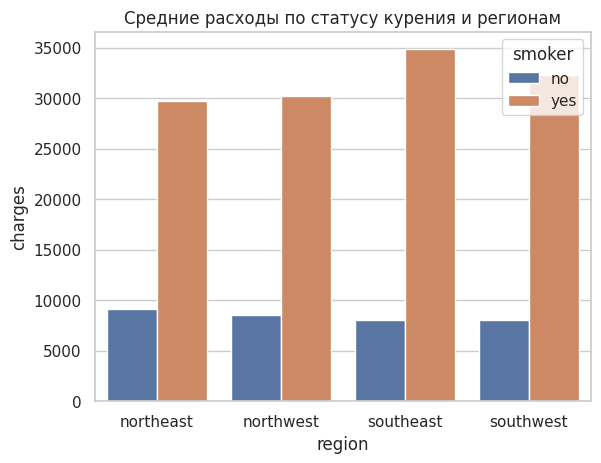

In [ ]:
df_group = df.groupby(["smoker", "region"])["charges"].mean().reset_index()
print(df_group)

sns.barplot(x="region", y="charges", hue="smoker", data=df_group)
plt.title("Средние расходы по статусу курения и регионам")
plt.show()


## 2. Объединение таблиц

Средний BMI и расходы по возрастным группам.

   age        bmi       charges
0   18  31.326159   7086.217556
1   19  28.596912   9747.909335
2   20  30.632759  10159.697736
3   21  28.185714   4730.464330
4   22  31.087679  10012.932802


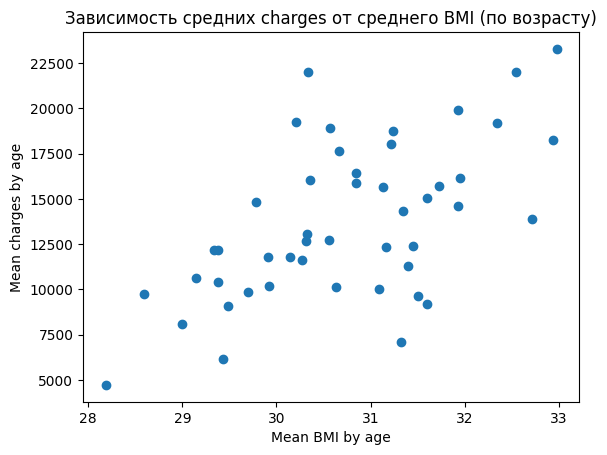

In [ ]:

bmi_by_age = df.groupby('age')['bmi'].mean().reset_index()

charges_by_age = df.groupby('age')['charges'].mean().reset_index()

merged = pd.merge(bmi_by_age, charges_by_age, on='age')
print(merged.head())

plt.scatter(merged['bmi'], merged['charges'])
plt.xlabel("Mean BMI by age")
plt.ylabel("Mean charges by age")
plt.title("Зависимость средних charges от среднего BMI (по возрасту)")
plt.show()


## 3. Возраст, курение и расходы

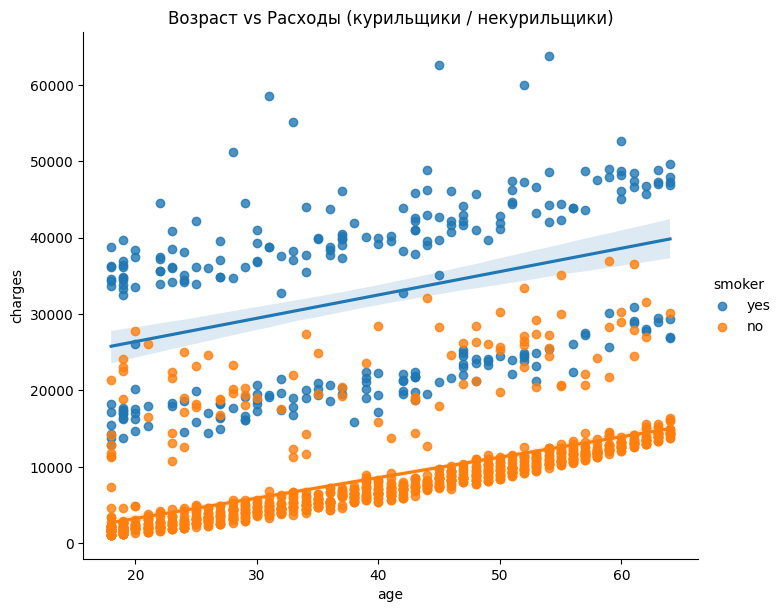

In [ ]:
sns.lmplot(x="age", y="charges", hue="smoker", data=df, height=6, aspect=1.2)
plt.title("Возраст vs Расходы (курильщики / некурильщики)")
plt.show()


## 4. Распределение BMI и связь с расходами

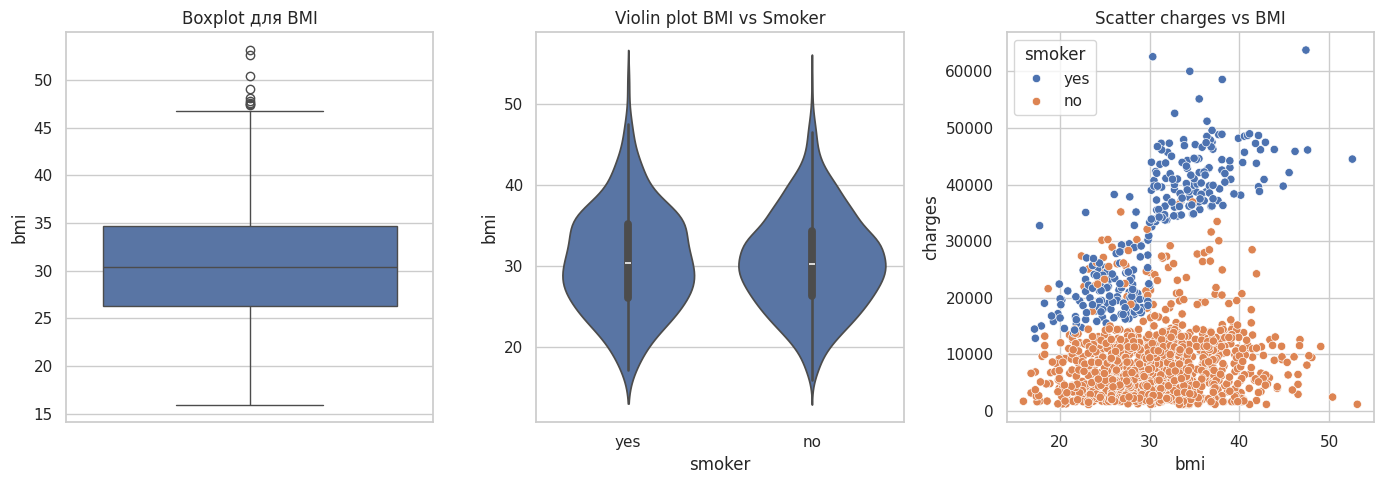

In [ ]:
plt.figure(figsize=(14,5))

plt.subplot(1,3,1)
sns.boxplot(y=df['bmi'])
plt.title("Boxplot для BMI")

plt.subplot(1,3,2)
sns.violinplot(x='smoker', y='bmi', data=df)
plt.title("Violin plot BMI vs Smoker")

plt.subplot(1,3,3)
sns.scatterplot(x='bmi', y='charges', hue='smoker', data=df)
plt.title("Scatter charges vs BMI")

plt.tight_layout()
plt.show()

## 5. Проверка нормальности

In [ ]:
stat, p = stats.shapiro(df["charges"].sample(1000))
print(f"Shapiro-Wilk test: statistic={stat:.3f}, p-value={p:.3e}")
if p > 0.05:
    print("Данные не отвергают гипотезу нормальности")
else:
    print("Данные не нормальны")


Shapiro-Wilk test: statistic=0.814, p-value=1.934e-32
Данные не нормальны


## 6. Признаки и target

Target `charges`: медицинские расходы. Анализируем связь с возрастом, BMI, числом детей, курением, полом и регионом. Для моделирования выделяем train и проводим EDA на нём.

Full dataset shape: (1338, 7)


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


Train shape: (1070, 7) Test shape: (268, 7)

--- train info ---


,age,sex,bmi,children,smoker,region,charges
count,1070.000000,1070,1070.000000,1070.000000,1070,1070,1070.000000
unique,NaN,2,NaN,NaN,2,4,NaN
top,NaN,male,NaN,NaN,no,southeast,NaN
freq,NaN,548,NaN,NaN,850,283,NaN
mean,39.357009,NaN,30.560397,1.107477,NaN,NaN,13346.089736
std,14.073960,NaN,6.043386,1.215983,NaN,NaN,12019.510778
min,18.000000,NaN,15.960000,0.000000,NaN,NaN,1121.873900
25%,27.000000,NaN,26.205000,0.000000,NaN,NaN,4897.667387
50%,39.500000,NaN,30.210000,1.000000,NaN,NaN,9575.442100
75%,51.000000,NaN,34.496250,2.000000,NaN,NaN,16746.657400



Категориальные распределения (train):


,sex,smoker,region
female,522.0,NaN,NaN
male,548.0,NaN,NaN
no,NaN,850.0,NaN
northeast,NaN,NaN,267.0
northwest,NaN,NaN,256.0
southeast,NaN,NaN,283.0
southwest,NaN,NaN,264.0
yes,NaN,220.0,NaN


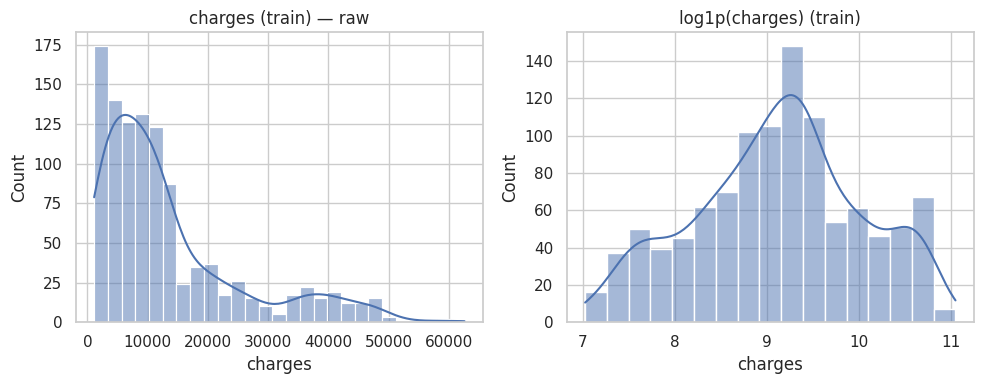

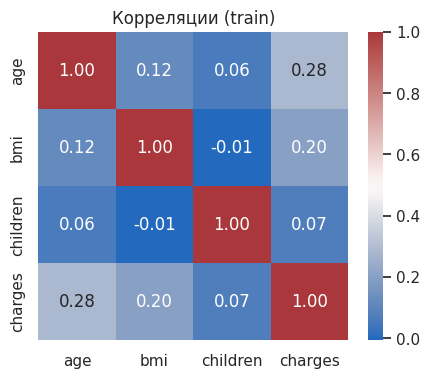

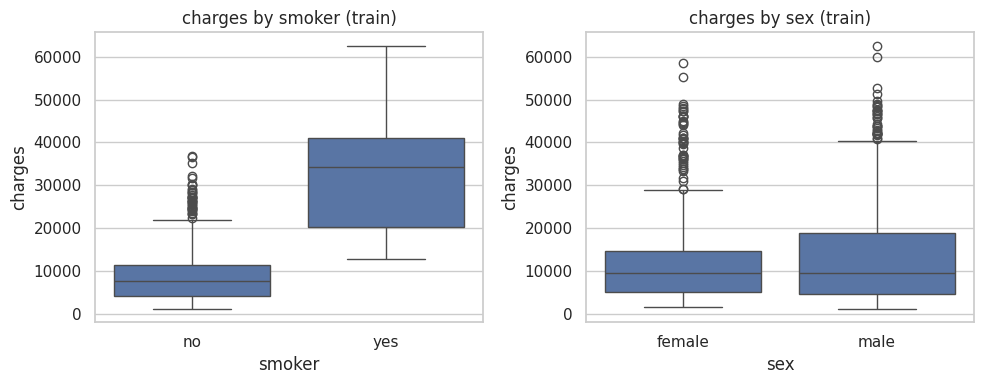

Выводы (на train):
- charges сильно скошены; лог-преобразование может помочь стабильности модели.
- 'smoker' заметно отделяет высокие charges - сильный предиктор.
- возраст и bmi положительно коррелируют с charges, но не идеально линейно.
- категориальные region/sex имеют меньший, но присутствующий эффект.


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

sns.set(style="whitegrid")

print("Full dataset shape:", df.shape)
display(df.head())

RANDOM_STATE = 42
train_df, test_df = train_test_split(df, test_size=0.2, random_state=RANDOM_STATE)
print("Train shape:", train_df.shape, "Test shape:", test_df.shape)

print("\n--- train info ---")
display(train_df.describe(include='all'))
print("\nКатегориальные распределения (train):")
display(train_df[['sex','smoker','region']].apply(lambda x: x.value_counts()))

plt.figure(figsize=(10,4))
plt.subplot(1,2,1)
sns.histplot(train_df['charges'], kde=True)
plt.title("charges (train) - raw")

plt.subplot(1,2,2)
sns.histplot(np.log1p(train_df['charges']), kde=True)
plt.title("log1p(charges) (train)")
plt.tight_layout()
plt.show()

num_cols = ['age','bmi','children','charges']
plt.figure(figsize=(5,4))
sns.heatmap(train_df[num_cols].corr(), annot=True, fmt=".2f", cmap="vlag")
plt.title("Корреляции (train)")
plt.show()

plt.figure(figsize=(10,4))
plt.subplot(1,2,1)
sns.boxplot(x='smoker', y='charges', data=train_df)
plt.title("charges by smoker (train)")
plt.subplot(1,2,2)
sns.boxplot(x='sex', y='charges', data=train_df)
plt.title("charges by sex (train)")
plt.tight_layout()
plt.show()

print("Выводы (на train):")
print("- charges сильно скошены; лог-преобразование может помочь стабильности модели.")
print("- 'smoker' заметно отделяет высокие charges - сильный предиктор.")
print("- возраст и bmi положительно коррелируют с charges, но не идеально линейно.")
print("- категориальные region/sex имеют меньший, но присутствующий эффект.")


### Наблюдения по train

`charges` скошены вправо. Курение связано с наиболее высокими расходами; возраст и BMI положительно коррелируют с target. Связи не полностью линейны.

## 7. OLS

OLS TRAIN: RMSE=6105.55, MAE=4208.23, R2=0.7417
OLS TEST : RMSE=5796.28, MAE=4181.19, R2=0.7836


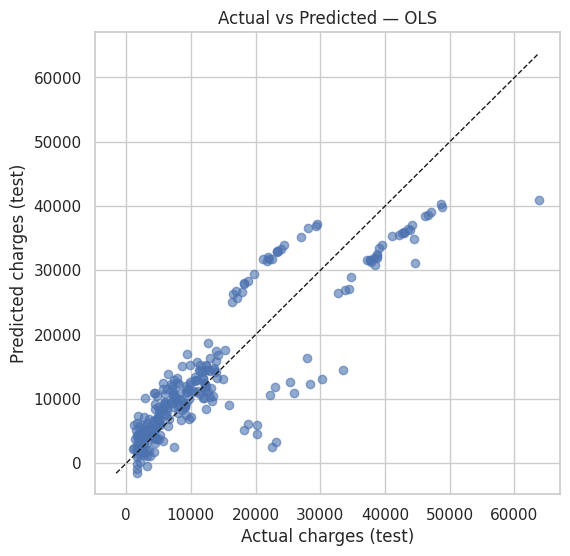

Intercept: 8955.244801502886


In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

feature_cols = ['age','sex','bmi','children','smoker','region']
target_col = 'charges'

X_train = train_df[feature_cols].copy()
y_train = train_df[target_col].copy()
X_test = test_df[feature_cols].copy()
y_test = test_df[target_col].copy()

numeric_features = ['age','bmi','children']
categorical_features = ['sex','smoker','region']

numeric_transformer = StandardScaler()
categorical_transformer = OneHotEncoder(drop='first', sparse_output=False)

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ],
    remainder='drop'
)

pipe_ols = Pipeline(steps=[
    ('pre', preprocessor),
    ('model', LinearRegression())
])

pipe_ols.fit(X_train, y_train)

def metrics(y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    mae = mean_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    return rmse, mae, r2

y_pred_train = pipe_ols.predict(X_train)
y_pred_test = pipe_ols.predict(X_test)

rmse_tr, mae_tr, r2_tr = metrics(y_train, y_pred_train)
rmse_te, mae_te, r2_te = metrics(y_test, y_pred_test)

print("OLS TRAIN: RMSE={:.2f}, MAE={:.2f}, R2={:.4f}".format(rmse_tr, mae_tr, r2_tr))
print("OLS TEST : RMSE={:.2f}, MAE={:.2f}, R2={:.4f}".format(rmse_te, mae_te, r2_te))

import matplotlib.pyplot as plt
plt.figure(figsize=(6,6))
plt.scatter(y_test, y_pred_test, alpha=0.6)
mn, mx = min(y_test.min(), y_pred_test.min()), max(y_test.max(), y_pred_test.max())
plt.plot([mn,mx], [mn,mx], 'k--', lw=1)
plt.xlabel("Actual charges (test)")
plt.ylabel("Predicted charges (test)")
plt.title("Actual vs Predicted - OLS")
plt.show()

ohe = pipe_ols.named_steps['pre'].named_transformers_['cat']
ohe_cols = ohe.get_feature_names_out(categorical_features)
all_cols = numeric_features + list(ohe_cols)
coefs = pipe_ols.named_steps['model'].coef_
coef_df = pd.DataFrame({'feature': all_cols, 'coef': coefs})
print("Intercept:", pipe_ols.named_steps['model'].intercept_)


### Результат OLS

Train: RMSE **6105,55**, MAE **4208,23**, R² **0,7417**. Test, 268 строк: RMSE **5796,28**, MAE **4181,19**, R² **0,7836**. Масштабирование и one-hot encoding обучаются на train внутри Pipeline.

## 8. Фильтрация выбросов и Lasso

In [ ]:
from sklearn.linear_model import Lasso
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np

def remove_outliers_iqr(X, y, numeric_cols, k=1.5, include_target=False):
    df = X.copy()
    df['_target_'] = y
    mask = np.ones(len(df), dtype=bool)

    cols = numeric_cols + (['_target_'] if include_target else [])
    for col in cols:
        Q1 = df[col].quantile(0.25)
        Q3 = df[col].quantile(0.75)
        IQR = Q3 - Q1
        lower, upper = Q1 - k*IQR, Q3 + k*IQR
        mask &= df[col].between(lower, upper)

    removed = (~mask).sum()
    return X[mask], y[mask], removed

X = df.drop(columns=['charges'])
y = df['charges']

numeric_features = ['age', 'bmi', 'children']
categorical_features = ['sex', 'smoker', 'region']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

numeric_transformer = StandardScaler()
categorical_transformer = OneHotEncoder(drop='first', sparse_output=False)

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)

def metrics(y_true, y_pred):
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mae = mean_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    return rmse, mae, r2

# IQR-фильтрация признаков и target.
X_train_aggr, y_train_aggr, n_removed_aggr = remove_outliers_iqr(
    X_train, y_train, numeric_features, k=1.5, include_target=True
)
print(f"[Агрессивное] Удалено выбросов: {n_removed_aggr}. Train: {len(X_train)} → {len(X_train_aggr)}")

pipe_lasso_aggr = Pipeline(steps=[
    ('preprocess', preprocessor),
    ('model', Lasso(max_iter=5000, random_state=42))
])

param_grid = {'model__alpha': [0.01, 0.1, 1, 10]}
grid_aggr = GridSearchCV(pipe_lasso_aggr, param_grid, cv=5, scoring='r2')
grid_aggr.fit(X_train_aggr, y_train_aggr)

y_pred_train_aggr = grid_aggr.predict(X_train_aggr)
y_pred_test_aggr = grid_aggr.predict(X_test)

rmse_tr_a, mae_tr_a, r2_tr_a = metrics(y_train_aggr, y_pred_train_aggr)
rmse_te_a, mae_te_a, r2_te_a = metrics(y_test, y_pred_test_aggr)

print(f"Lasso (агрессивное) TRAIN: RMSE={rmse_tr_a:.2f}, MAE={mae_tr_a:.2f}, R2={r2_tr_a:.4f}")
print(f"Lasso (агрессивное) TEST : RMSE={rmse_te_a:.2f}, MAE={mae_te_a:.2f}, R2={r2_te_a:.4f}\n")

# IQR-фильтрация только признаков.
X_train_soft, y_train_soft, n_removed_soft = remove_outliers_iqr(
    X_train, y_train, numeric_features, k=2.0, include_target=False
)
print(f"[Мягкое] Удалено выбросов: {n_removed_soft}. Train: {len(X_train)} → {len(X_train_soft)}")

pipe_lasso_soft = Pipeline(steps=[
    ('preprocess', preprocessor),
    ('model', Lasso(max_iter=5000, random_state=42))
])

grid_soft = GridSearchCV(pipe_lasso_soft, param_grid, cv=5, scoring='r2')
grid_soft.fit(X_train_soft, y_train_soft)

y_pred_train_soft = grid_soft.predict(X_train_soft)
y_pred_test_soft = grid_soft.predict(X_test)

rmse_tr_s, mae_tr_s, r2_tr_s = metrics(y_train_soft, y_pred_train_soft)
rmse_te_s, mae_te_s, r2_te_s = metrics(y_test, y_pred_test_soft)

print(f"Lasso (мягкое) TRAIN: RMSE={rmse_tr_s:.2f}, MAE={mae_tr_s:.2f}, R2={r2_tr_s:.4f}")
print(f"Lasso (мягкое) TEST : RMSE={rmse_te_s:.2f}, MAE={mae_te_s:.2f}, R2={r2_te_s:.4f}\n")

print("OLS TRAIN: RMSE=6105.55, MAE=4208.23, R2=0.7417")
print("OLS TEST : RMSE=5796.28, MAE=4181.19, R2=0.7836")


[Агрессивное] Удалено выбросов: 116. Train: 1070 → 954
Lasso (агрессивное) TRAIN: RMSE=4585.33, MAE=2584.64, R2=0.5920
Lasso (агрессивное) TEST : RMSE=7458.81, MAE=4182.61, R2=0.6416

[Мягкое] Удалено выбросов: 1. Train: 1070 → 1069
Lasso (мягкое) TRAIN: RMSE=6102.90, MAE=4216.77, R2=0.7419
Lasso (мягкое) TEST : RMSE=5806.32, MAE=4206.05, R2=0.7828

OLS TRAIN: RMSE=6105.55, MAE=4208.23, R2=0.7417
OLS TEST : RMSE=5796.28, MAE=4181.19, R2=0.7836


### Сравнение сценариев

- Фильтрация по IQR с учётом target: удалено 116 train-строк (1070 → 954), test RMSE **7458,81**, R² **0,6416**.
- Фильтрация только признаков: удалена одна строка (1070 → 1069), test RMSE **5806,32**, R² **0,7828**.
- OLS: test RMSE **5796,28**, R² **0,7836**. Lasso не улучшил результат; удаление дорогих страховок ухудшило качество.

`alpha` подбирается через GridSearchCV (`cv=5`, scoring R²); преобразования входят в Pipeline. IQR-пороги рассчитаны до внутренней CV. Один test используется для нескольких сценариев, поэтому дальнейший выбор требует отдельной validation-выборки. В конце ячейки OLS-метрики повторены константами. Подвыборка для Shapiro-Wilk не имеет фиксированного seed.